# 03 - External Dataset Preparation

**Project:** DetectIt – Intelligent Web Threat Detection Using Machine Learning

**Goal:** A model can get a very high score on its own test set and still fail on new data. To check how our model works in the real world, we test it on a second dataset that was collected by different people at a different time: the [Web Page Phishing Detection Dataset](https://www.kaggle.com/datasets/shashwatwork/web-page-phishing-detection-dataset) (Hannousse & Yahiouche, 2021).

In this notebook, we clean this dataset, make sure it does not share any URLs with PhiUSIIL, create 40 URL features, and split it into a training part (80%) and a test part (20%). In Experiment 2, the training part is added to the PhiUSIIL training set, and the test part is used to test the models on URLs from a different source.

**Input:** `data/dataset_phishing.csv`, `data/PhiUSIIL_Phishing_URL_Dataset.csv`

**Output:** `data/processed/external_train.csv`, `data/processed/external_test.csv`, `data/processed/external_train_urls.csv`, `data/processed/external_test_urls.csv`

## Setup

We load the libraries, our feature functions from `src/features.py`, and keep all settings in one place.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sys.path.append(str(Path("..").resolve()))
from src.features import build_all_url_features, normalize_url

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

EXTERNAL_PATH = Path("../data/dataset_phishing.csv")
PHIUSIIL_PATH = Path("../data/PhiUSIIL_Phishing_URL_Dataset.csv")
PROCESSED_DIR = Path("../data/processed")
RESULTS_DIR = Path("../results")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

TARGET = "label"
TEST_SIZE = 0.2
RANDOM_STATE = 42
LABEL_NAMES = {0: "Legitimate", 1: "Phishing"}
CLASS_PALETTE = {"Legitimate": "#4C72B0", "Phishing": "#C44E52"}

In [2]:
ext = pd.read_csv(EXTERNAL_PATH)
initial_shape = ext.shape
print(f"Loaded external dataset: {initial_shape[0]:,} rows | {initial_shape[1]} columns")

Loaded external dataset: 11,430 rows | 89 columns


## 1. Dataset Overview

This dataset has a `url` column, 87 features and a `status` column (the label). Its 87 features are different from the PhiUSIIL features, so a model trained on PhiUSIIL cannot use them. Because of this, we only keep the `url` and `status` columns, and we create our own features from the URL.

In [3]:
ext[["url", "status"]].head()

,url,status
0,http://www.crestonwood.com/router.php,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,phishing
2,https://support-appleld.com.secureupdate.duila...,phishing
3,http://rgipt.ac.in,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,legitimate


In [4]:
print(f"Missing values: {ext.isnull().sum().sum()}")
print(f"Label values: {ext['status'].unique().tolist()}")

Missing values: 0
Label values: ['legitimate', 'phishing']


## 2. Remove Duplicate URLs

Just like in PhiUSIIL, we check whether any URL appears more than once, and whether a repeated URL has two different labels. We then keep only the first copy of each URL.

Before comparing, we make the URLs consistent: we remove extra spaces, make all letters lowercase and remove a `/` at the end. Without this step, `http://example.com/login/` and `http://example.com/login` would look like two different URLs. This matters because a copy of a URL in the training part and another copy in the test part would make the test unfair.

In [5]:
url_key = ext["url"].map(normalize_url)
dup_mask = url_key.duplicated(keep=False)
conflicts = ext[dup_mask].groupby(url_key[dup_mask])["status"].nunique().gt(1).sum()

print(f"Exact duplicate URLs: {ext['url'].duplicated().sum()}")
print(f"Duplicate URLs after making them consistent: {url_key.duplicated().sum()}")
print(f"Duplicated URLs with different labels: {conflicts}")

ext = ext[~url_key.duplicated()].reset_index(drop=True)
print(f"Rows remaining: {len(ext):,}")

Exact duplicate URLs: 1
Duplicate URLs after making them consistent: 174
Duplicated URLs with different labels: 0
Rows remaining: 11,256


## 3. Change the Label

The label in this dataset is text: `legitimate` or `phishing`. We turn it into numbers in the same way as PhiUSIIL, so that **1 = Phishing** and **0 = Legitimate**.

In [6]:
ext[TARGET] = ext["status"].map({"legitimate": 0, "phishing": 1})

print(f"Labels that could not be converted: {ext[TARGET].isnull().sum()}")
ext[TARGET].map(LABEL_NAMES).value_counts()

Labels that could not be converted: 0


label
Legitimate    5715
Phishing      5541
Name: count, dtype: int64

## 4. Remove URLs Shared with PhiUSIIL

If a URL is in both datasets, the model has already seen it during training, and the external test would not be fair. We make the URLs of both datasets consistent in the same way as in Section 2, compare them and remove every shared URL from this dataset.

In [7]:
phiusiil_urls = set(pd.read_csv(PHIUSIIL_PATH, usecols=["URL"])["URL"].map(normalize_url))
is_shared = ext["url"].map(normalize_url).isin(phiusiil_urls)

print(f"URLs also found in PhiUSIIL: {is_shared.sum()}")
print(ext.loc[is_shared, TARGET].map(LABEL_NAMES).value_counts().to_string())

ext = ext[~is_shared].reset_index(drop=True)
print(f"\nRows remaining: {len(ext):,}")

URLs also found in PhiUSIIL: 172
label
Legitimate    124
Phishing       48

Rows remaining: 11,084


## 5. Class Distribution

After cleaning, we check that the dataset is still balanced.

In [8]:
class_counts = ext[TARGET].map(LABEL_NAMES).value_counts()
class_pct = (class_counts / len(ext) * 100).round(2)
pd.DataFrame({"Count": class_counts, "Percentage (%)": class_pct})

,Count,Percentage (%)
label,,
Legitimate,5591,50.44
Phishing,5493,49.56


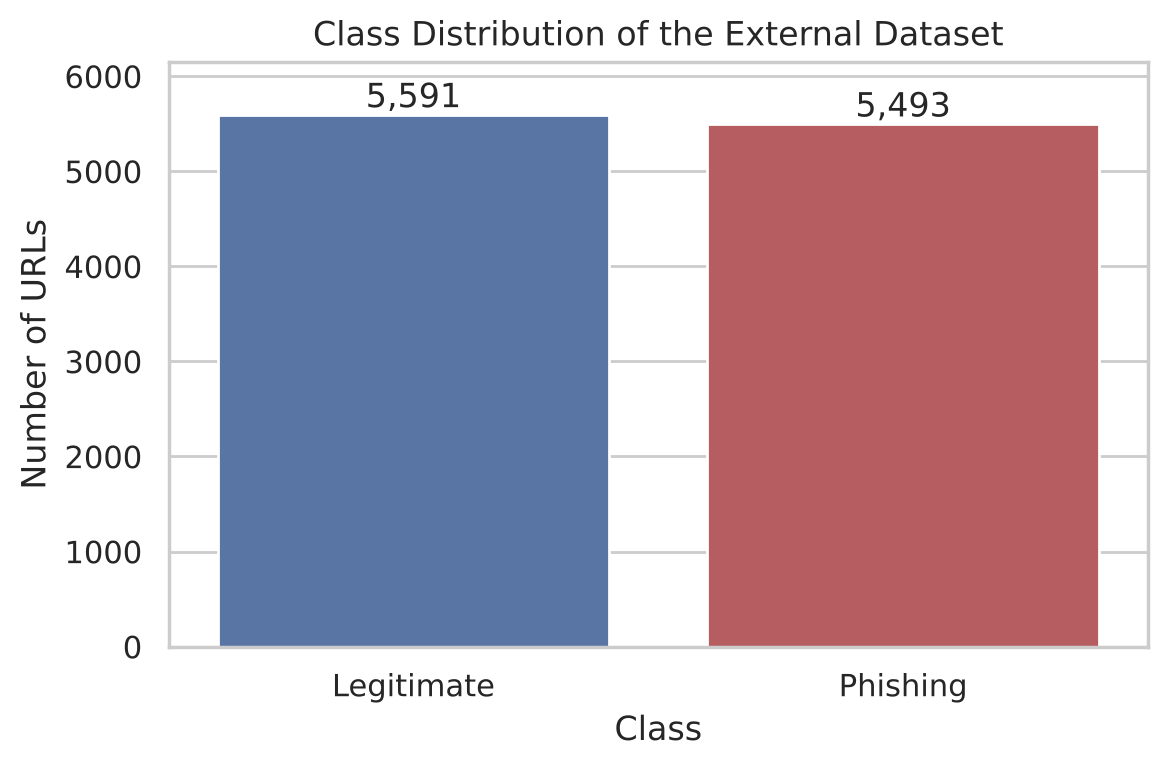

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
class_labels = ext[TARGET].map(LABEL_NAMES)
sns.countplot(x=class_labels, hue=class_labels, order=["Legitimate", "Phishing"], palette=CLASS_PALETTE, legend=False, ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}")

ax.margins(y=0.1)
ax.set_title("Class Distribution of the External Dataset")
ax.set_xlabel("Class")
ax.set_ylabel("Number of URLs")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "external_class_distribution.png", dpi=300)
plt.show()

### Findings: Data Cleaning

- The dataset has 11,430 URLs and no missing values.
- Only 1 URL appeared twice in exactly the same form. But after making the URLs consistent, **174 URLs were repeated**, mostly the same phishing URL with and without a `/` at the end. None of them had two different labels. We kept only the first copy of each, which leaves 11,256 URLs.
- **172 URLs were also in PhiUSIIL** (124 legitimate and 48 phishing). We removed them, so the external dataset only contains URLs that are not in PhiUSIIL.
- After cleaning, there are **11,084 URLs**: 5,591 legitimate (50.4%) and 5,493 phishing (49.6%). The dataset is still balanced.

## 6. Create URL Features

We create 40 features from each URL with the `build_all_url_features` function from `src/features.py`:

- **18 URL features** that we already made in `02_preprocessing.ipynb`, such as `FullURLLength`, `PathDepth` and `URLEntropy`.
- **22 new URL features**, for example the length and type of the TLD (`.com`, `.xyz`), the share of digits, letters and special characters, the number of query parameters, whether the URL uses a URL shortener, and whether a brand name such as `paypal` appears outside the real domain.

The same function is used for PhiUSIIL in Experiment 2, so both datasets get exactly the same features, calculated in exactly the same way. We do not create the 8 page features, because they need page columns from PhiUSIIL that this dataset does not have.

Each feature is calculated from one URL only. It does not use other URLs or the labels, so creating the features before the train/test split does not cause data leakage.

In [10]:
external_features = build_all_url_features(ext["url"])
print(f"Created {external_features.shape[1]} URL features for {len(external_features):,} URLs")
external_features.head()

Created 40 URL features for 11,084 URLs


,FullURLLength,HostLength,PathLength,QueryLength,PathDepth,NoOfDotsInURL,NoOfHyphensInURL,NoOfSlashesInURL,NoOfDigitsInHost,HostSubdomainCount,SuspiciousWordCount,URLEntropy,HostEntropy,HasAtSymbol,HasHTTPSScheme,HostIsIP,HostHasHyphen,HasDoubleSlashInPath,TLDLength,IsSuspiciousTLD,IsCommonTLD,NoOfDigitsInURL,DigitRatioInURL,LetterRatioInURL,SpecialCharRatioInURL,NoOfUppercaseInURL,NoOfQueryParams,NoOfPercentInURL,NoOfUnderscoreInURL,HasPort,HasWWW,HostTokenCount,LongestHostToken,LongestPathToken,HasFileExtension,IsShortener,BrandOutsideDomain,HasPunycode,HostVowelRatio,MaxConsecutiveDigits
0,37,19,11,0,1,3,0,3,0,1,0,3.787043,3.195296,0,0,0,0,0,3,0,1,0,0.000000,0.810811,0.189189,0,0,0,0,0,1,3,11,6,1,0,0,0,0.294118,0
1,77,23,47,0,3,1,0,5,0,0,0,4.393890,3.708132,0,0,0,0,0,3,0,1,17,0.220779,0.688312,0.090909,1,0,0,0,0,0,2,19,32,0,0,0,0,0.363636,3
2,126,50,20,47,2,4,1,5,0,3,3,4.753412,3.999080,0,1,0,1,0,3,0,1,19,0.150794,0.698413,0.150794,0,3,0,2,0,0,6,13,15,0,0,1,0,0.377778,3
3,18,11,0,0,0,2,0,2,0,1,0,3.461320,3.095795,0,0,0,0,0,2,0,0,0,0.000000,0.722222,0.277778,0,0,0,0,0,0,3,5,0,0,0,0,0,0.333333,0
4,55,15,33,0,2,2,2,5,0,1,0,4.097662,3.189898,0,0,0,0,0,3,0,1,0,0.000000,0.818182,0.181818,0,0,0,0,0,1,3,7,11,0,0,0,0,0.307692,0


## 7. Compare the Two Datasets

A model only works well on new data if the new data looks similar to the data it learned from. Here we compare the average value of some URL features in both datasets, for each class.

In [11]:
train_urls = pd.read_csv(PROCESSED_DIR / "train_urls.csv")["URL"]
train_labels = pd.read_csv(PROCESSED_DIR / "train.csv", usecols=[TARGET])[TARGET]
phiusiil_features = build_all_url_features(train_urls)

compare_cols = ["FullURLLength", "PathDepth", "NoOfHyphensInURL", "SuspiciousWordCount", "URLEntropy", "HasHTTPSScheme", "HasWWW", "IsCommonTLD"]
comparison = pd.concat({
    "PhiUSIIL (training set)": phiusiil_features[compare_cols].groupby(train_labels.map(LABEL_NAMES).values).mean().T,
    "External dataset": external_features[compare_cols].groupby(ext[TARGET].map(LABEL_NAMES).values).mean().T,
}, axis=1)
comparison.round(2)

PhiUSIIL (training set)          External dataset         
                                 Legitimate Phishing       Legitimate Phishing
FullURLLength                         27.23    46.14            47.84    75.52
PathDepth                              0.00     0.58             1.40     2.27
NoOfHyphensInURL                       0.08     0.70             1.23     0.79
SuspiciousWordCount                    0.01     0.10             0.04     0.45
URLEntropy                             3.85     4.10             4.07     4.32
HasHTTPSScheme                         1.00     0.48             0.43     0.34
HasWWW                                 1.00     0.42             0.66     0.21
IsCommonTLD                            0.84     0.51             0.85     0.71

### Findings: Comparing the Datasets

- In both datasets, phishing URLs are longer, more random (`URLEntropy`) and contain more suspicious words than legitimate URLs. So the main patterns are the same.
- However, the **legitimate URLs are very different**. In PhiUSIIL, legitimate URLs are almost always just a home page (`https://www.example.com`): they have no path (`PathDepth` = 0), are short (27 characters on average), and all of them use HTTPS and start with `www`. In the external dataset, legitimate URLs often point to inner pages (average `PathDepth` = 1.4), are longer (48 characters), only 43% use HTTPS and 66% start with `www`.
- Because of this, a model trained on PhiUSIIL may learn simple rules such as "a URL with a path is phishing" or "a URL without HTTPS is phishing". These rules work on PhiUSIIL but will cause many false alarms on the external dataset. To fix this, we also use part of this dataset for training (Section 8).
- We therefore **expect a model trained only on PhiUSIIL to score much lower on this dataset**. This is an important result, because it shows how much the choice of dataset affects how well a phishing detector works in the real world.

## 8. Split into Training and Test Parts

The comparison above shows that a model trained only on PhiUSIIL has never seen legitimate inner-page URLs like the ones in this dataset. To fix this, we give the model some URLs from this dataset during training.

We split the dataset into **80% for training** and **20% for testing**, the same split we used for PhiUSIIL. We use a stratified split, so both parts keep the same share of phishing and legitimate URLs, and `random_state=42`, so we get the same split every time. The test part is never used for training.

In [12]:
train_idx, test_idx = train_test_split(
    ext.index,
    test_size=TEST_SIZE,
    stratify=ext[TARGET],
    random_state=RANDOM_STATE,
)

split_check = pd.DataFrame({
    "Rows": [len(train_idx), len(test_idx)],
    "Phishing (%)": [ext.loc[train_idx, TARGET].mean() * 100, ext.loc[test_idx, TARGET].mean() * 100],
}, index=["Training part", "Test part"])
split_check.round(2)

,Rows,Phishing (%)
Training part,8867,49.55
Test part,2217,49.57


In [13]:
shared_urls = set(ext.loc[train_idx, "url"].map(normalize_url)) & set(ext.loc[test_idx, "url"].map(normalize_url))
print(f"URLs in both the training part and the test part: {len(shared_urls)}")

URLs in both the training part and the test part: 0


## 9. Save the Files

We save the URL features with the label for each part (`external_train.csv` and `external_test.csv`), and the URLs in separate files (`external_train_urls.csv` and `external_test_urls.csv`). The URL files are used later to look at the URLs that the models get wrong. The rows are in the same order in the feature file and the URL file.

In [14]:
external = external_features.assign(**{TARGET: ext[TARGET].values})

for part, idx in [("train", train_idx), ("test", test_idx)]:
    external.loc[idx].to_csv(PROCESSED_DIR / f"external_{part}.csv", index=False)
    ext.loc[idx, ["url"]].to_csv(PROCESSED_DIR / f"external_{part}_urls.csv", index=False)
    print(f"Saved external_{part}.csv: {len(idx):,} rows | {external.shape[1] - 1} features + 1 label")

Saved external_train.csv: 8,867 rows | 40 features + 1 label
Saved external_test.csv: 2,217 rows | 40 features + 1 label


In [15]:
print(f"Before: {initial_shape[0]:,} rows | {initial_shape[1]} columns")
print(f"After:  {len(ext):,} rows | {external.shape[1]} columns ({external.shape[1] - 1} URL features + 1 label)")

Before: 11,430 rows | 89 columns
After:  11,084 rows | 41 columns (40 URL features + 1 label)


## Summary

| Step | What We Did | Result |
|---|---|---|
| 1. Overview | Kept only the `url` and `status` columns | 11,430 URLs, no missing values |
| 2. Duplicates | Made the URLs consistent and removed repeated URLs | 174 rows removed |
| 3. Label | Changed the label to 1 = Phishing, 0 = Legitimate | Same format as PhiUSIIL |
| 4. Shared URLs | Removed URLs that are also in PhiUSIIL | 172 rows removed |
| 5. Class balance | Checked the class distribution | 49.6% phishing, 50.4% legitimate |
| 6. URL features | Created the 18 URL features from PhiUSIIL and 22 new URL features | 40 features |
| 7. Comparison | Compared URL features between the two datasets | Legitimate URLs look very different |
| 8. Split | Stratified 80/20 split with `random_state=42` | 8,867 training URLs, 2,217 test URLs |
| 9. Save | Saved the features and the URLs of both parts | Ready for Experiment 2 |

The training part will be added to the PhiUSIIL training set in Experiment 2, and the test part will show how well the models work on URLs from a different source.